In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Data Load

In [2]:
df = pd.read_csv("Salary_Data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


# Exploratory Data Analysis (EDA)

In [3]:
df.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


Minimum maaş 350 → outlier olabilir.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


## Missing Values

In [5]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

En fazla 5 eksik değer var, çok az.

## Duplicate Satırlar

In [6]:
df.duplicated().sum()

np.int64(4912)

Satırların çoğu kopya. Model sonuçlarını etkileyebilir. Ek denemelerde test etmeliyiz

## Unique Değerler

In [7]:
df.nunique()

Age                     41
Gender                   3
Education Level          7
Job Title              193
Years of Experience     37
Salary                 444
dtype: int64

Education Level 7 farklı değer gösteriyor ama normalde 4 eğitim seviyesi var.

In [8]:
# education level: aynı seviye farklı yazılmış
df["Education Level"].value_counts()

Education Level
Bachelor's Degree    2267
Master's Degree      1573
PhD                  1368
Bachelor's            756
High School           448
Master's              288
phD                     1
Name: count, dtype: int64

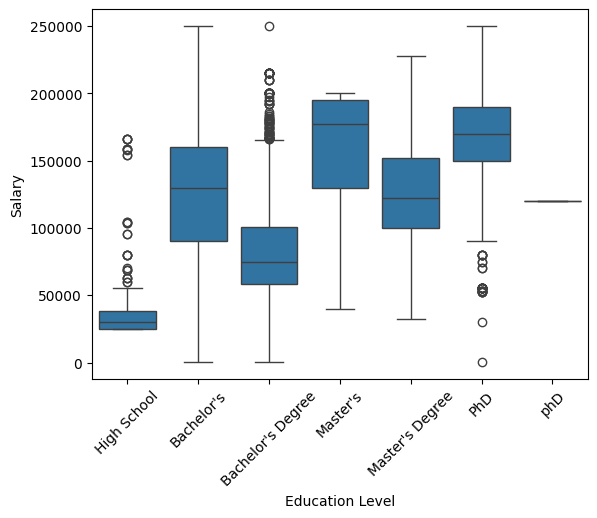

In [9]:
# eğitim seviyesine göre maaş
sns.boxplot(x="Education Level", y="Salary", data=df,
            order=["High School", "Bachelor's", "Bachelor's Degree", "Master's", "Master's Degree", "PhD", "phD"])
plt.xticks(rotation=45)
plt.show()

Eğitim arttıkça maaş artıyor. Ama Bachelor's ile Bachelor's Degree nin maaşları birbirinden farklı çıktı.Aynı diploma olmalarına rağmen Master's için de aynı durum var

## Correlation Matrix

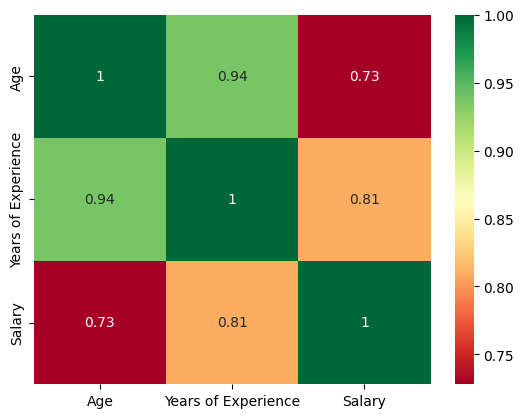

In [10]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="RdYlGn")
plt.show()

## Experience - Salary İlişkisi

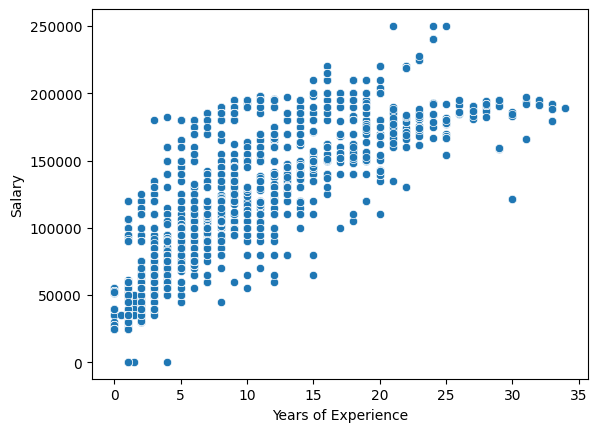

In [11]:
sns.scatterplot(x="Years of Experience", y="Salary", data=df)
plt.show()

İlişki düz değil. Eğri önce hızlı artıyor sonra yavaşlıyor

# Data Cleaning

## Missing Values Delete

In [12]:
# sadece Salary'si boş olanlar
df.dropna(subset=["Salary"], inplace=True)
df.shape

(6699, 6)

Salary'si boş olan satırlar ne train'de ne test'te kullanılabilir, bu yüzden bölmeden önce siliyoruz. Diğer eksik değerleri bölmeden sonra sileceğiz.

# Train / Test Split

In [13]:
X = df.drop(columns=["Salary"])
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (5359, 5)
Test: (1340, 5)


Bundan sonraki bütün işlemler sadece trainden öğrenilip teste uygulanacak 

# Data Preprocessing

## Missing Values Delete (train ve test ayrı)

In [14]:
X_train = X_train.dropna()
y_train = y_train[X_train.index]
X_test = X_test.dropna()
y_test = y_test[X_test.index]
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (5358, 5)
Test: (1340, 5)


## Outlier Temizliği

In [15]:
# sınırları sadece train'den hesapla
q1 = y_train.quantile(0.25)
q3 = y_train.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print(lower_bound, upper_bound)

-65000.0 295000.0


In [16]:
# aynı sınırları train ve test'e uygula
train_mask = (y_train > lower_bound) & (y_train < upper_bound)
test_mask = (y_test > lower_bound) & (y_test < upper_bound)

X_train, y_train = X_train[train_mask], y_train[train_mask]
X_test, y_test = X_test[test_mask], y_test[test_mask]
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (5358, 5)
Test: (1340, 5)


Sınırlar çok geniş çıktı, hiç satır silinmedi. 350 gibi düşük maaşlar IQR ile yakalanamıyor.

## Education Level Düzeltme

In [17]:
# sıraya göre numara ver
education_map = {
    "High School": 0,
    "Bachelor's": 1,
    "Bachelor's Degree": 1,
    "Master's": 2,
    "Master's Degree": 2,
    "PhD": 3,
    "phD": 3,
}
X_train["Education Level"] = X_train["Education Level"].map(education_map)
X_test["Education Level"] = X_test["Education Level"].map(education_map)
X_train["Education Level"].value_counts()

Education Level
1    2438
2    1477
3    1092
0     351
Name: count, dtype: int64

Lise < Lisans < Yüksek Lisans < Doktora sırası korundu (ordinal encoding).

## Gender Encoding

In [18]:
le = LabelEncoder()
X_train["Gender"] = le.fit_transform(X_train["Gender"])
X_test["Gender"] = le.transform(X_test["Gender"])

# Feature Engineering

## Job Title: Rare Class ve One-Hot Encoding

In [19]:
# 5'ten az geçen ünvanlar rare (sadece train'e bakarak)
counts = X_train["Job Title"].value_counts()
common_titles = counts[counts >= 5].index
print("Yaygın ünvan sayısı:", len(common_titles))

Yaygın ünvan sayısı: 64


In [20]:
# yaygın olmayan ünvanları "Other" yap
X_train["Job Title"] = X_train["Job Title"].where(X_train["Job Title"].isin(common_titles), "Other")
X_test["Job Title"] = X_test["Job Title"].where(X_test["Job Title"].isin(common_titles), "Other")

Test'te train'de hiç görülmemiş bir ünvan varsa o da "Other" oluyor.

In [21]:
# one-hot encoding
X_train = pd.get_dummies(X_train, columns=["Job Title"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["Job Title"], dtype=int)

# test'in sütunlarını train ile aynı yap
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
X_train.shape

(5358, 69)

Ünvanların sırası yok, bu yüzden LabelEncoder yerine one-hot encoding.

## Experience Karesi

In [22]:
X_train["Experience_sq"] = X_train["Years of Experience"] ** 2
X_test["Experience_sq"] = X_test["Years of Experience"] ** 2

Experience - Salary ilişkisi eğri olduğu için kare terimi ekledik.

# Scaling

In [23]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Model: Linear Regression

In [24]:
model = LinearRegression()
model.fit(X_train_s, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [25]:
y_pred = model.predict(X_test_s)

In [26]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [27]:
mae

13484.384092206405

In [28]:
r2

0.8795064328444785

Sınıfta yapılan: 0.67 → şu anki skor: 0.88

# Modeli İyileştirme Denemeleri

## 1. Decision Tree

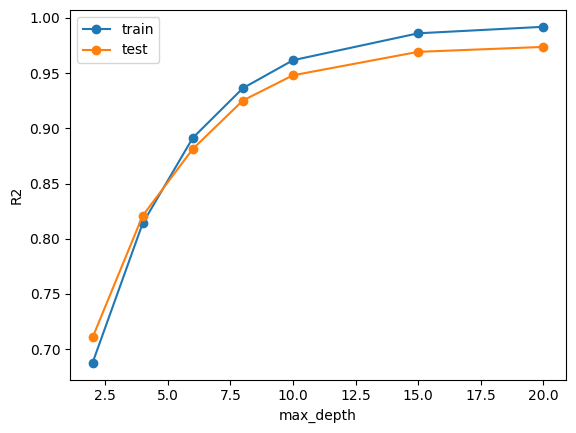

In [29]:
derinlikler = [2, 4, 6, 8, 10, 15, 20]
train_skor = []
test_skor = []

for d in derinlikler:
    tree = DecisionTreeRegressor(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    train_skor.append(tree.score(X_train, y_train))
    test_skor.append(tree.score(X_test, y_test))

plt.plot(derinlikler, train_skor, marker="o", label="train")
plt.plot(derinlikler, test_skor, marker="o", label="test")
plt.xlabel("max_depth")
plt.ylabel("R2")
plt.legend()
plt.show()

In [30]:
test_skor

[0.7105525558491264,
 0.8208738693271354,
 0.8813137028151832,
 0.9252159418425474,
 0.9480583147818404,
 0.9693102651399912,
 0.973782844121963]

Test skoru 0.97'ye çıktı. Duplicate satırlar olduğundan ezber şüphesi var.

## 2. Duplicate Satırları Silmek

In [31]:
train = X_train.copy()
train["Salary"] = y_train
test = X_test.copy()
test["Salary"] = y_test

# train içindeki kopyaları sil
train = train.drop_duplicates()

# test'te olup train'de de bulunan satırları sil
test = test.drop_duplicates()
test = test.merge(train, how="left", indicator=True)
test = test[test["_merge"] == "left_only"].drop(columns=["_merge"])

print("Train:", train.shape)
print("Test:", test.shape)

Train: (1557, 71)
Test: (212, 71)


In [32]:
X_train_u = train.drop(columns=["Salary"])
y_train_u = train["Salary"]
X_test_u = test.drop(columns=["Salary"])
y_test_u = test["Salary"]

In [33]:
# linear regression (kopyasız)
X_train_s = scaler.fit_transform(X_train_u)
X_test_s = scaler.transform(X_test_u)
model.fit(X_train_s, y_train_u)
r2_score(y_test_u, model.predict(X_test_s))

0.8719954776762574

In [34]:
# decision tree (kopyasız)
tree = DecisionTreeRegressor(max_depth=20, random_state=42)
tree.fit(X_train_u, y_train_u)
tree.score(X_test_u, y_test_u)

0.8550064937837787

Kopyalar silinince decision tree 0.97'den 0.86'ya düştü, Linear Regression ise 0.87 ile daha iyi çıktı. Ağacın yüksek skoru ezbermiş.

# Sonuçlar

| Adım | R2 |
|---|---|
| Sınıfta yapılan | 0.67 |
| Linear Regression | 0.88 |
| 1. Decision Tree | 0.97 (ezber şüphesi) |
| 2. Kopyasız: Linear Regression | 0.87 |
| 2. Kopyasız: Decision Tree | 0.86 |

**Final model: Linear Regression (R2 = 0.88, kopyasız testte 0.87)**